# **Εργασία 6 - Συνδυασμός Μοντέλων**

**Ακριτίδου Ελένη**

---



In [1]:
#Ερώτημα1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

files.upload()
df = pd.read_csv("water_potability.csv")

print(df.shape)
print(df.isna().sum())
df.head()

Saving water_potability.csv to water_potability (1).csv
(3276, 10)
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [2]:
X = df.drop(columns="Potability")
y = df["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=0
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (2948, 9)  Test: (328, 9)


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = {}

def run_search(name, pipe, param_grid):
    gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)

    best = gs.best_estimator_
    results[name] = {
        "Train accuracy": best.score(X_train, y_train),
        "Hyperparameter tuning avg accuracy": gs.best_score_,
        "Test accuracy": best.score(X_test, y_test),
    }

    print("Καλύτεροι παράμετροι:", gs.best_params_)
    print("Μέση ακρίβεια CV:", round(gs.best_score_, 4))
    return gs

In [5]:
#Ερώτημα2

pipe_dt = Pipeline([
    ("imputer", SimpleImputer()),
    ("model", DecisionTreeClassifier(random_state=0))
])

grid_dt = {
    "imputer__strategy": ["mean", "median"],
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10],
}

gs_dt = run_search("Decision Tree", pipe_dt, grid_dt)

Καλύτεροι παράμετροι: {'imputer__strategy': 'mean', 'model__criterion': 'gini', 'model__max_depth': 7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20}
Μέση ακρίβεια CV: 0.6499


In [6]:
#Ερώτημα3

pipe_rf = Pipeline([
    ("imputer", SimpleImputer()),
    ("model", RandomForestClassifier(random_state=0))
])

grid_rf = {
    "imputer__strategy": ["mean", "median"],
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [1, 2, 5],
}

gs_rf = run_search("Random Forest", pipe_rf, grid_rf)

Καλύτεροι παράμετροι: {'imputer__strategy': 'mean', 'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Μέση ακρίβεια CV: 0.6808


In [7]:
#Ερώτημα4

pipe_bag = Pipeline([
    ("imputer", SimpleImputer()),
    ("model", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=0),
                                random_state=0))
])

grid_bag = {
    "imputer__strategy": ["mean", "median"],
    "model__n_estimators": [10, 50, 100],
    "model__max_samples": [0.5, 0.8, 1.0],
    "model__max_features": [0.5, 0.8, 1.0],
    "model__estimator__max_depth": [5, 10, None],
}

gs_bag = run_search("Bagging", pipe_bag, grid_bag)

Καλύτεροι παράμετροι: {'imputer__strategy': 'mean', 'model__estimator__max_depth': 10, 'model__max_features': 1.0, 'model__max_samples': 1.0, 'model__n_estimators': 100}
Μέση ακρίβεια CV: 0.6781


In [8]:
#Ερώτηση5

knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(weights="distance"))
])

stack = StackingClassifier(
    estimators=[
        ("dt", DecisionTreeClassifier(random_state=0)),
        ("knn", knn_pipe),
        ("gnb", GaussianNB()),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

pipe_stack = Pipeline([
    ("imputer", SimpleImputer()),
    ("model", stack)
])

grid_stack = {
    "imputer__strategy": ["mean", "median"],
    "model__dt__max_depth": [3, 5, 10],
    "model__knn__knn__n_neighbors": [5, 11, 21],
}

gs_stack = run_search("Stacking", pipe_stack, grid_stack)

Καλύτεροι παράμετροι: {'imputer__strategy': 'median', 'model__dt__max_depth': 10, 'model__knn__knn__n_neighbors': 21}
Μέση ακρίβεια CV: 0.6621


In [9]:
#Ερώτηση6

pipe_xgb = Pipeline([
    ("imputer", SimpleImputer()),
    ("model", XGBClassifier(random_state=0, eval_metric="logloss"))
])

grid_xgb = {
    "imputer__strategy": ["mean", "median"],
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}

gs_xgb = run_search("XGBoost", pipe_xgb, grid_xgb)

Καλύτεροι παράμετροι: {'imputer__strategy': 'mean', 'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__n_estimators': 100, 'model__subsample': 0.8}
Μέση ακρίβεια CV: 0.672


,Train accuracy,Hyperparameter tuning avg accuracy,Test accuracy
Decision Tree,0.7266,0.6499,0.6402
Random Forest,0.9912,0.6808,0.6677
Bagging,0.8440,0.6781,0.6555
Stacking,1.0000,0.6621,0.6585
XGBoost,0.8901,0.6720,0.6250


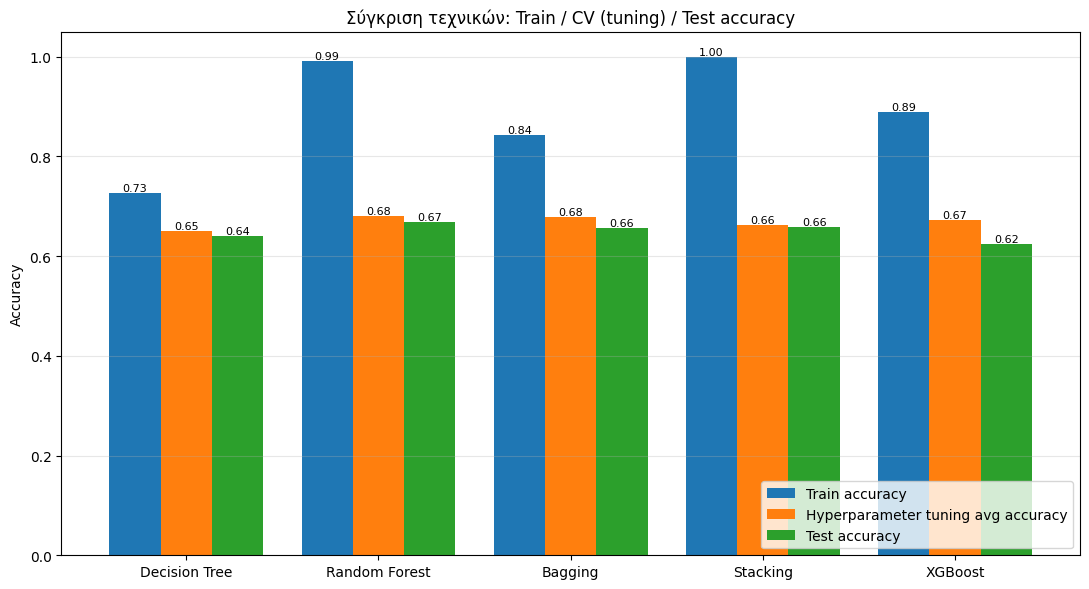

In [10]:
#Ερώτημα7

res_df = pd.DataFrame(results).T.round(4)
display(res_df)

ax = res_df.plot(kind="bar", figsize=(11, 6), width=0.8)
ax.set_title("Σύγκριση τεχνικών: Train / CV (tuning) / Test accuracy")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)

plt.tight_layout()
plt.show()

**Παρατήρηση:**

Συγκρίναμε πέντε τεχνικές ταξινόμησης (Decision Tree, Random Forest, Bagging, Stacking, XGBoost) για την πόσιμότητα του νερού. Το Random Forest ήταν το καλύτερο μοντέλο συνολικά, με την υψηλότερη μέση ακρίβεια στο cross validation (0.681) και το υψηλότερο test accuracy (0.668). Ακολούθησαν το Stacking (0.659) και το Bagging (0.656) στο test, ενώ το απλό Decision Tree είχε 0.640. Το XGBoost, παρότι στο cross validation ήταν τρίτο (0.672), είχε το χαμηλότερο test accuracy (0.625), χαμηλότερο ακόμη και από το μονό δέντρο. Τα μοντέλα συνδυασμού βελτίωσαν γενικά το δέντρο στο cross validation κατά 1.5–3 ποσοστιαίες μονάδες. Αυτό είναι αναμενόμενο, αφού ο συνδυασμός πολλών μοντέλων μειώνει τη διακύμανση των προβλέψεων. Έντονο overfitting παρουσίασαν το Stacking (train accuracy 1.00 έναντι 0.66 στο cross validation) και το Random Forest (0.99 έναντι 0.68). Το XGBoost (0.89) και το Bagging (0.84) είχαν μετριότερη απόκλιση, και το Decision Tree τη μικρότερη (0.73), γιατί περιορίστηκε από το max_depth=7 και το min_samples_split=20. Η στρατηγική συμπλήρωσης ελλιπών τιμών είχε μικρή επίδραση: το mean επιλέχθηκε σε τέσσερα από τα πέντε μοντέλα και το median μόνο στο Stacking. Συνολικά, όλα τα μοντέλα κινήθηκαν μεταξύ 62% και 68% στο test, κοντά στο ποσοστό της πλειοψηφούσας κλάσης (περίπου 61%). Αυτό δείχνει ότι τα χαρακτηριστικά του dataset δεν διαχωρίζουν εύκολα το πόσιμο από το μη πόσιμο νερό και ότι ο συνδυασμός μοντέλων βοηθά, αλλά δεν λύνει το πρόβλημα. Επιπλέον, το test set έχει μόνο 328 δείγματα, οπότε οι διαφορές των 1–2 μονάδων μεταξύ των μοντέλων δεν είναι ασφαλές να θεωρηθούν στατιστικά σημαντικές.